# 3. Editing & Extending Models

Now it's your turn to take control of the CSV files, rebuild the Julia ODEs with `CSV2Model`, and watch how biological perturbations reshape the dynamics!

:::{tip} Editing CSVs directly in the browser
When doing research in the lab, you can edit `reactions.csv`, `parameters.csv`, and `ratelaws.csv` in Excel or VS Code. Here in this interactive tutorial, we write the CSV tables straight from Julia code cells using `write(...)` so you can test ideas in seconds — and every change runs inside your own isolated workspace!
:::

First, let's load our Julia packages.

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()
println("Ready to build and modify models!")

Ready to build and modify models!


---

## Challenge 1: Make the expression of A 10× slower

In the original Toy Model, `k1_Aexp = 1`.
Try lowering `k1_Aexp` by **10×** (from `1` to `0.1`).

- **Hint**: You only need to change `parameters.csv`!
- Before running the cell, predict what will happen to **A**, **B**, and **C**.

*(We give each experiment its own model filename like `toyModel_slow.jl` so we can inspect and compare models cleanly without overwriting the original starter files.)*

In [2]:
# Edit k1_Aexp below (try 0.1 for 10x slower expression!)
write("parameters_slow.csv", """Parameter,Value
k1_Aexp,0.1
k1_AtoB,2
k1_BtoC,3
k1_Cdeg,4
""")

# Rebuild the Julia ODE model from reactions.csv + our modified parameters
run(`python3 csv2model-multiscale.py reactions.csv parameters_slow.csv ratelaws.csv toyModel_slow.jl`)
include("toyModel_slow.jl")
include("variableNames.jl")

# Inspect the updated equations!
print(read("toyModel_slow.jl", String))

inline
Running CSV2JuliaDiffEq with parameters hard-coded into the CSV file, if this is not correct, re-run with the 5th argument set to 'scan'
Opening ratelaws.csv as rate law file
Opening parameters_slow.csv as parameters file
Opening reactions.csv as reactions file
#######################################################
# Generated programmatically by CSV2JuliaDiffEq.      #
# http://github.com/SiFTW/CSV2JuliaDiffEq             #
#######################################################
# generated from:
#    reactions file: reactions.csv
#    parameters file file: parameters_slow.csv
#    rate law file: ratelaws.csv
#
# Statistics:
#    Equations:3
#    Parameters:4
#######################################################



function toyModel_slow(dy,y,p,t)
	A=maximum([y[1],0])
	B=maximum([y[2],0])
	C=maximum([y[3],0])
	#A
	dy[1]= + 0.1 - A * 2
	#B
	dy[2]= + A * 2 - B * 3
	#C
	dy[3]= + B * 3 - C * 4
end


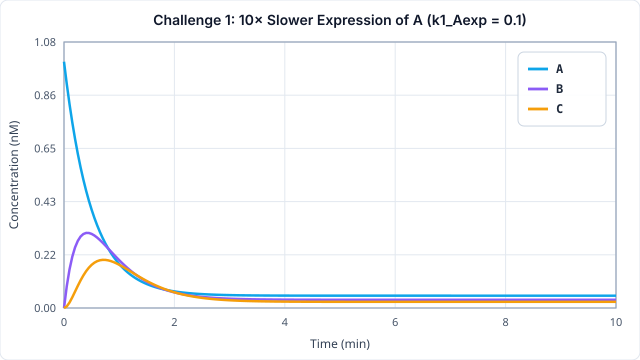

In [3]:
y0 = [1.0, 0.0, 0.0]
prob_slow = ODEProblem(ODEFunction(toyModel_slow), y0, (0.0, 10.0))
sol_slow = solve(prob_slow, abstol=1e-5, reltol=1e-3)

plot(
    sol_slow,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 1: 10× Slower Expression of A (k1_Aexp = 0.1)",
    lw = 2.5,
)

Notice that **A** drops to a much lower steady state (`0.05 nM` instead of `0.5 nM`) — and so do **B** and **C**, because they are downstream of **A**!

---

## Challenge 2: Make A expressed 10× faster AND C degraded 10× faster

Now set:
- `k1_Aexp = 10` (10× faster than its original value of `1`)
- `k1_Cdeg = 40` (10× faster than its original value of `4`)

What happens to the concentrations of **A**, **B**, and **C**? Notice why **A** and **B** jump up by 10× while **C** ends up right back at its original steady state of `0.25 nM`!

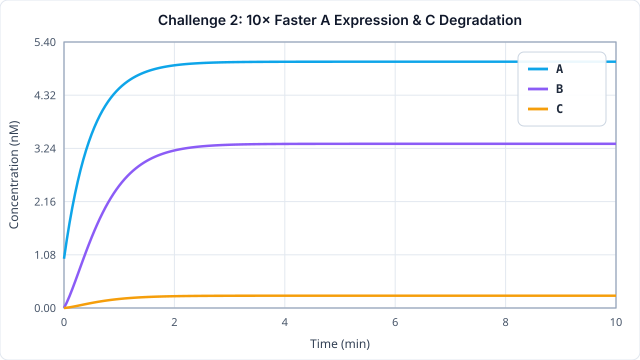

In [4]:
write("parameters_fast.csv", """Parameter,Value
k1_Aexp,10
k1_AtoB,2
k1_BtoC,3
k1_Cdeg,40
""")

run(`python3 csv2model-multiscale.py reactions.csv parameters_fast.csv ratelaws.csv toyModel_fast.jl`)
include("toyModel_fast.jl")
include("variableNames.jl")

prob_fast = ODEProblem(ODEFunction(toyModel_fast), [1.0, 0.0, 0.0], (0.0, 10.0))
sol_fast = solve(prob_fast, abstol=1e-5, reltol=1e-3)

plot(
    sol_fast,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 2: 10× Faster A Expression & C Degradation",
    lw = 2.5,
)

---

## Challenge 3: Add a brand-new molecular species D!

Let's extend our network so that **C** turns into a new protein **D**, and **D** degrades:

```{figure} ../images/toy-model-abcd.svg
:alt: Extended 4-species Toy Model diagram A to B to C to D
:width: 100%

The extended 4-species cascade: $\emptyset \to A \to B \to C \to D \to \emptyset$.
```

To add species **D**, we need to update **3 things**:
1. **Reactions CSV**: Add a new row for `C → D` (`k1_CtoD`), and change the degradation row so that **D** (not **C**) is the substrate degrading away (`k1_Ddeg`).
2. **Parameters CSV**: Add a numerical value for `k1_CtoD` (e.g. `2`) and `k1_Ddeg` (e.g. `4`).
3. **Initial conditions `y0`**: Provide **4** starting concentrations instead of 3, e.g. `y0 = [1.0, 0.0, 0.0, 0.0]`.

Run the two cells below to generate `toyModel_ABCD.jl`, inspect its 4 equations, and simulate the extended pathway!

In [5]:
# 1. Updated reactions table with 5 arrows (C -> D and D -> nothing)
write("reactions_ABCD.csv", """Substrate,Products,Kinetic Law,Modifiers,Parameters
,A,Constant Exp,,k1_Aexp
A,B,Mass Action with substrate,,k1_AtoB
B,C,Mass Action with substrate,,k1_BtoC
C,D,Mass Action with substrate,,k1_CtoD
D,,Mass Action with substrate,,k1_Ddeg
""")

# 2. Updated parameters table with k1_CtoD and k1_Ddeg
write("parameters_ABCD.csv", """Parameter,Value
k1_Aexp,1
k1_AtoB,2
k1_BtoC,3
k1_CtoD,2
k1_Ddeg,4
""")

# Generate the 4-species ODE model automatically!
run(`python3 csv2model-multiscale.py reactions_ABCD.csv parameters_ABCD.csv ratelaws.csv toyModel_ABCD.jl`)
include("toyModel_ABCD.jl")
include("variableNames.jl")

print(read("toyModel_ABCD.jl", String))

inline
Running CSV2JuliaDiffEq with parameters hard-coded into the CSV file, if this is not correct, re-run with the 5th argument set to 'scan'
Opening ratelaws.csv as rate law file
Opening parameters_ABCD.csv as parameters file
Opening reactions_ABCD.csv as reactions file
#######################################################
# Generated programmatically by CSV2JuliaDiffEq.      #
# http://github.com/SiFTW/CSV2JuliaDiffEq             #
#######################################################
# generated from:
#    reactions file: reactions_ABCD.csv
#    parameters file file: parameters_ABCD.csv
#    rate law file: ratelaws.csv
#
# Statistics:
#    Equations:4
#    Parameters:5
#######################################################



function toyModel_ABCD(dy,y,p,t)
	A=maximum([y[1],0])
	B=maximum([y[2],0])
	C=maximum([y[3],0])
	D=maximum([y[4],0])
	#A
	dy[1]= + 1 - A * 2
	#B
	dy[2]= + A * 2 - B * 3
	#C
	dy[3]= + B * 3 - C * 2
	#D
	dy[4]= + C * 2 - D * 4
end


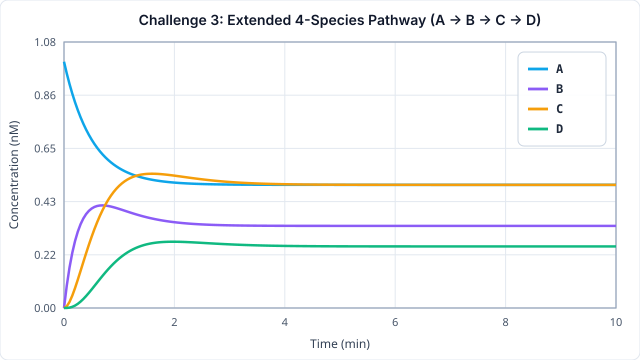

In [6]:
# 3. Four initial conditions for [A, B, C, D]
y0_ABCD = [1.0, 0.0, 0.0, 0.0]

prob_ABCD = ODEProblem(ODEFunction(toyModel_ABCD), y0_ABCD, (0.0, 10.0))
sol_ABCD = solve(prob_ABCD, abstol=1e-5, reltol=1e-3)

plot(
    sol_ABCD,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Challenge 3: Extended 4-Species Pathway (A → B → C → D)",
    lw = 2.5,
)

---

## Free Play Sandbox!

Congratulations! You have built, inspected, perturbed, and extended your own ODE model in Julia.

Use the open sandbox cell below to invent your own experiments:
- Add a 5th species **E**, or add a **branching pathway** where **B** turns into both **C** and **D**!
- Rename the proteins to real signalling molecules (e.g., `IKK`, `IkB`, `NFkB`).
- Try adding a **reversible reaction** (`B → A`) or a new **Michaelis–Menten rate law** (`{kcat} * [S1] / ({Km} + [S1])`) to `ratelaws_custom.csv`!
- Print `read("myCustomModel.jl", String)` after running `CSV2Model` to check how your custom CSVs turn into Julia equations.

In [ ]:
# Experiment freely! Edit reactions, parameters, or rate laws below and run.
write("ratelaws_custom.csv", """Rate Law Name,Rate Law Definition
Constant Exp,{k1}
Mass Action with substrate,[S1] * {k1}
Michaelis Menten,{k1} * [S1] / ({k2} + [S1])
""")

write("reactions_custom.csv", """Substrate,Products,Kinetic Law,Modifiers,Parameters
,A,Constant Exp,,k1_Aexp
A,B,Michaelis Menten,,k1_vmax k2_km
B,C,Mass Action with substrate,,k1_BtoC
C,,Mass Action with substrate,,k1_Cdeg
""")

write("parameters_custom.csv", """Parameter,Value
k1_Aexp,1.0
k1_vmax,3.0
k2_km,0.5
k1_BtoC,2.0
k1_Cdeg,4.0
""")

run(`python3 csv2model-multiscale.py reactions_custom.csv parameters_custom.csv ratelaws_custom.csv myCustomModel.jl`)
include("myCustomModel.jl")
include("variableNames.jl")

prob_custom = ODEProblem(ODEFunction(myCustomModel), [1.0, 0.0, 0.0], (0.0, 10.0))
sol_custom = solve(prob_custom, abstol=1e-5, reltol=1e-3)

plot(
    sol_custom,
    label = permutedims(syms),
    xlabel = "Time (min)",
    ylabel = "Concentration (nM)",
    title = "Custom Model (with Michaelis–Menten A → B)",
    lw = 2.5,
)